# Chile: Anexo 1 de la RAN 21-13 sobre un balance en pesos y UF

**Pregunta:** ¿qué riesgo de tasa de interés asigna el Anexo 1 del regulador chileno a un banco con un balance en pesos y en UF, qué choque decide su delta EVE y su delta NII, cuánto los cambian la compensación de 50 por ciento y el cargo por reajustabilidad, y el banco cruza una línea que lo hace priorizado para la supervisión?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 05 de este tema
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar por qué el regulador chileno trata la UF como una moneda propia (la UR) con su propia curva, tamaños de choque, piso y cargo, y leer los dos tramos de un balance en CLP y UF;
- reconstruir con el motor las curvas de los dos tramos desde los rendimientos observados, y decir qué le falta a la curva en pesos;
- calcular el delta EVE de cada tramo bajo los seis choques, combinar los dos tramos con la regla de compensación de 50 por ciento y obtener el delta EVE del Anexo 1;
- calcular el delta NII de cada tramo, sumar el cargo por reajustabilidad y obtener el delta NII del Anexo 1;
- aplicar las tres pruebas que hacen priorizado a un banco, y leer la distancia de cada tasa con choque a su piso.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C15: **Banco Andino**, un banco **sintético** con un balance en pesos chilenos (CLP) y en UF (la unidad de cuenta reajustable chilena, CLF), a la fecha de valoración 2026-09-03. Sus agregados están calibrados a las cifras del sistema del informe de agosto de 2026 de la CMF (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, el regulador chileno, estadísticas públicas de la clase de licencia `mirror-allowed`); la proporción en UF, el perfil de reprecio de cada partida, la separación de depósitos y todo supuesto de comportamiento son sintéticos y están declarados en el documento. Las **curvas son reales**: los rendimientos del Banco Central de Chile (cuadro F022 de la BDE, `mirror-allowed`, atribución "Fuente: Banco Central de Chile, Base de Datos Estadísticos") y el valor de la UF de la fecha (serie F073.UFF.PRE.Z.D). El dinero está en millones de CLP; el tramo UF está en millones de CLF y se convierte con el valor de la UF solo donde se suman los dos tramos. El motor nunca convierte entre monedas.

El caso versiona seis variantes del mismo banco, cada una una tensión distinta sobre el balance: `short-uf` (corto neto en UF a 30 por ciento del Tier 1), `long-uf` (largo neto), `cpi-surprise` (largo neto, con una sorpresa de inflación de 2,5 puntos), `clp-steepener` (un balance en pesos más largo), `offset-on-off` (la regla de compensación comparada con y sin) y `floors-active` (70 por ciento de los préstamos comerciales en UF a tasa flotante, para poner en juego los pisos).

- **Archivos que se leen:** `data/derived/C15/short-uf.json`, `long-uf.json`, `cpi-surprise.json`, `clp-steepener.json`, `offset-on-off.json` y `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `cpi_scenario`, `thresholds`) y `models-banco-andino-2026-09.json` (`fit.annex1_table`, `multipliers`, `nmd_caps`, `buckets`).

La celda siguiente carga los siete archivos e imprime el aviso del banco y los nombres de las variantes.

In [2]:
# Cargar las seis variantes y el documento de modelos (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C15"
ids = ["short-uf", "long-uf", "cpi-surprise", "clp-steepener", "offset-on-off", "floors-active"]
variants = {v: json.loads((derived / f"{v}.json").read_text(encoding="utf-8")) for v in ids}
fit = json.loads((derived / "models-banco-andino-2026-09.json").read_text(encoding="utf-8"))["fit"]
out = variants["short-uf"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento"}
NAME.update({"flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja"})
NAME.update({"delta-eve": "delta EVE", "delta-nii": "delta NII", "on": "con", "off": "sin"})
NAME.update({"compared": "comparada", True: "sí", False: "no"})
print(out["bank"]["notice"][LANG])
print("variantes:", ids)

Banco Andino es un banco sintético. Los agregados de su balance están calibrados a los agregados del sistema de la CMF de agosto de 2026; la proporción en UF, el perfil de reprecio de cada partida, la separación de depósitos y todo supuesto de comportamiento son sintéticos y están declarados en el documento. Las curvas son reales: los rendimientos F022 del Banco Central de Chile de la fecha de valoración.
variantes: ['short-uf', 'long-uf', 'cpi-surprise', 'clp-steepener', 'offset-on-off', 'floors-active']


## Método

El Anexo 1 del capítulo 21-13 de la Recopilación Actualizada de Normas de la CMF (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf; dossier 03, F.2) define dos medidas estándar del riesgo de tasa de interés del libro de banca, ambas por moneda significativa: el **delta NII** (balance constante, los flujos de reprecio hasta un año) y el **delta EVE** (balance en extinción, todos los flujos de reprecio). Se construye sobre el estándar de Basilea (SRP31), con las particularidades chilenas que este notebook recorre: la UF como moneda propia, una tabla propia de tamaños de choque, un piso propio, un cargo por reajustabilidad, una regla de compensación entre el peso y la UF, y tres pruebas que hacen "priorizado" a un banco para la supervisión.

### Paso 1: la UF como una sola moneda, la UR

Los préstamos y depósitos chilenos suelen estar indexados a la UF, una unidad cuyo valor en pesos sigue a la inflación. El Anexo 1 dice que "los flujos en moneda local reajustable son tratados como una sola moneda, que denominaremos UR" (CLF, el peso reajustable por UF). El riesgo de esa moneda no es solo la tasa real: el **riesgo de reajustabilidad** es la exposición a pérdidas por cambios adversos en las unidades de reajustabilidad. El notebook mantiene entonces dos tramos. El tramo CLP lleva los flujos nominales en pesos en millones de CLP; el tramo UR lleva los flujos en UF en millones de CLF. La **posición neta en UF** $PN_{UR}$ es la diferencia entre activos y pasivos en UF, convertida a pesos con el valor de la UF de la fecha. La celda siguiente imprime los dos tramos y recalcula $PN_{UR}$.

Todos los flujos reajustables (UF) se tratan como una sola moneda, UR (RAN 21-13 Anexo 1).
valor de la UF al 2026-09-03 : 40877.73 CLP
     partidas          activos          pasivos    posición neta
CLP        12     4,988,540.25     3,917,062.27     1,071,477.98  CLP
UR          5            65.89            71.94            -6.05  CLF
PN_UR = -247264.15 millones de CLP
posición neta en UF sobre el Tier 1: -0.3


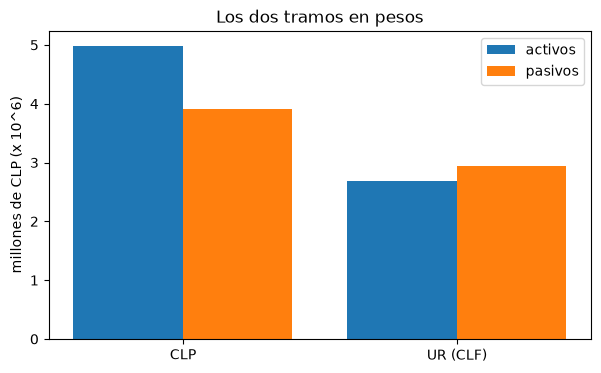

In [3]:
# Los dos tramos del banco en sus propias unidades, la posición neta en UF en pesos y los tramos en pesos
uf = out["ur_currency"]["uf_value"]
print(out["ur_currency"]["definition"][LANG])
print("valor de la UF al", out["ur_currency"]["uf_date"], ":", uf, "CLP")
print(f"{'':4s} {'partidas':>8s} {'activos':>16s} {'pasivos':>16s} {'posición neta':>16s}")
for leg in out["legs"]:
    totals = (leg["assets_total"], leg["liabilities_total"], leg["net_position"])
    cells = " ".join(f"{t:16,.2f}" for t in totals)
    print(f"{leg['leg']:4s} {len(leg['items']):8d} {cells}  {leg['currency']}")
pn_ur = out["legs"][1]["net_position"] * uf
print("PN_UR =", round(pn_ur, 2), "millones de CLP")
print("posición neta en UF sobre el Tier 1:", round(pn_ur / out["thresholds"]["tier1"], 4))
fig, ax = plt.subplots(figsize=(7, 4))
for j, leg in enumerate(out["legs"]):
    factor = uf if leg["currency"] == "CLF" else 1.0
    a_tot, l_tot = leg["assets_total"] * factor / 1e6, leg["liabilities_total"] * factor / 1e6
    ax.bar(j - 0.2, a_tot, 0.4, color="tab:blue", label="activos" if j == 0 else None)
    ax.bar(j + 0.2, l_tot, 0.4, color="tab:orange", label="pasivos" if j == 0 else None)
ax.set_xticks([0, 1], ["CLP", "UR (CLF)"])
ax.set_ylabel("millones de CLP (x 10^6)")
ax.set_title("Los dos tramos en pesos")
ax.legend()
plt.show()

El tramo en pesos es todo el balance en tamaño: activos de unos 5,0 billones de pesos frente a pasivos de 3,9 billones. El tramo en UF parece diminuto, 65,89 y 71,94 millones de CLF, pero cada UF vale 40.877,73 pesos, así que convertido es un tramo de unos 2,7 y 2,9 billones de pesos, y su posición neta de -6,05 millones de CLF es -247.264 millones de CLP, el -0,3 del Tier 1 que la variante está construida para tener. Los dos tramos no son comparables en sus propias unidades, y por eso el motor nunca convierte y el notebook convierte solo aquí y donde se suman los tramos. Lo que la imagen no muestra es el calendario de cada tramo, que es lo que llevan las curvas y las 19 bandas.

### Paso 2: las dos curvas

Cada tramo se descuenta con su propia curva. El notebook reconstruye ambas desde los rendimientos observados del documento con el motor, en los mismos tres pasos que el notebook 01: `bootstrap_zero_curve` convierte los rendimientos a la par en tasas cero con capitalización continua, `fit_nelson_siegel` les ajusta una curva suave y `nelson_siegel_yield` la evalúa en los 19 puntos medios. La curva UF tiene cuatro plazos publicados (2, 5, 10 y 30 años). La curva en pesos tiene solo tres (2, 5 y 10 años) y el ajuste Nelson-Siegel del motor necesita cuatro puntos, así que el proceso del producto agrega la tasa de política monetaria del Banco Central, la tasa a un día, como cuarto punto a 1/360 de año. Es una **tasa de política y no un rendimiento de mercado secundario**, una elección de Contraste que el documento declara como pregunta abierta. La celda siguiente reconstruye ambas curvas, imprime sus parámetros y las curvas en algunas bandas, y las dibuja.

CLP: plazos (años) [2.8e-03 2.0e+00 5.0e+00 1.0e+01]
    Nelson-Siegel β0 0.06045 β1 -0.01546 β2 -0.01807 τ 1.00
    error (pb) 0.500
UR: plazos (años) [ 2.  5. 10. 30.]
    Nelson-Siegel β0 0.03029 β1 -0.01825 β2 -0.00080 τ 2.50
    error (pb) 0.412
banda  1 |   0.0028 | CLP 0.04499 | UR 0.01205
banda  6 |   0.8750 | CLP 0.04564 | UR 0.01478
banda 10 |   3.5000 | CLP 0.05171 | UR 0.02024
banda 15 |   8.5000 | CLP 0.05651 | UR 0.02490
banda 19 |  25.0000 | CLP 0.05911 | UR 0.02839


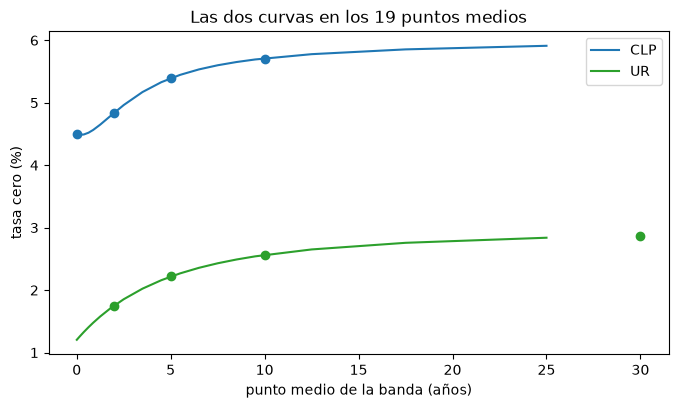

In [4]:
# Reconstruir las dos curvas desde los rendimientos observados y evaluarlas en los 19 puntos medios
r0, observed = {}, {}
for leg, key in (("CLP", "clp"), ("UR", "ur")):
    block = out["curves"][key]
    tenors = np.array([p["tenor_years"] for p in block["points"]])
    par = np.array([p["observed_yield"] for p in block["points"]])
    zero = curves.bootstrap_zero_curve(tenors, par, 2)
    ns = curves.fit_nelson_siegel(tenors, zero)
    r0[leg] = curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau)
    observed[leg] = (tenors, zero)
    print(f"{leg}: plazos (años) {np.round(tenors, 4)}")
    print(f"    Nelson-Siegel β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f}")
    print(f"    error (pb) {ns.rmse * 1e4:.3f}")
for k in (0, 5, 9, 14, 18):
    print(f"banda {k + 1:2d} | {MID[k]:8.4f} | CLP {r0['CLP'][k]:.5f} | UR {r0['UR'][k]:.5f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for leg, colour in (("CLP", "tab:blue"), ("UR", "tab:green")):
    ax.plot(MID, r0[leg] * 100, color=colour, label=leg)
    ax.plot(observed[leg][0], observed[leg][1] * 100, "o", color=colour)
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("tasa cero (%)")
ax.set_title("Las dos curvas en los 19 puntos medios")
ax.legend()
plt.show()

Las líneas son las curvas Nelson-Siegel en los 19 puntos medios y los puntos las tasas cero observadas a las que se ajustaron. La curva en pesos queda cerca de 4,5 por ciento en la banda más corta y sube a unos 5,9 por ciento a 25 años; la curva UF, una tasa real, parte en 1,2 por ciento y termina cerca de 2,8, de modo que la curva nominal queda unos tres puntos sobre la real, la compensación por inflación que cobra el mercado. El ajuste en pesos tiene solo tres rendimientos de mercado y la tasa de política como primer punto, así que su extremo corto es una tasa de política y no un rendimiento de mercado, una elección abierta que el documento declara y que un validador debe leer como un límite. Los ajustes son ceñidos, 0,50 y 0,41 pb, pero un ajuste ceñido sobre cuatro puntos no es mucha evidencia.

### Paso 3: las bandas, los topes de depósitos y los multiplicadores

Las 19 bandas y sus puntos medios son los del estándar de Basilea (notebook 01, paso 1); el Anexo repite los puntos medios. Los topes de los depósitos a la vista son los de Basilea (SRP31, Tabla 4) con los nombres chilenos: minorista con relación operacional (90 por ciento, 5 años), minorista sin ella (70 por ciento, 4,5 años) y mayorista (50 por ciento, 4 años); el motor acepta ambos nombres (`retail-operational` es `retail-transactional`). El Anexo repite también los multiplicadores por choque de la tasa de prepago y del rescate anticipado de depósitos a plazo (SRP31.119, SRP31.125). La celda siguiente divide con el motor los tres segmentos de depósitos del banco y aplica los multiplicadores a las tasas base del propio banco, y dibuja ambos.

retail-operational       pedido 0.95/5.5 y
    -> 0.90/5.0 y | tope aplicado sí
retail-non-operational   pedido 0.70/4.0 y
    -> 0.70/4.0 y | tope aplicado no
wholesale                pedido 0.60/4.5 y
    -> 0.50/4.0 y | tope aplicado sí
tasas base: CPR 0.05 | TDRR 0.05
paralelo al alza       CPR 0.0400 | TDRR 0.0600
paralelo a la baja     CPR 0.0600 | TDRR 0.0400
empinamiento           CPR 0.0400 | TDRR 0.0400
aplanamiento           CPR 0.0600 | TDRR 0.0600
corto al alza          CPR 0.0400 | TDRR 0.0600
corto a la baja        CPR 0.0600 | TDRR 0.0400


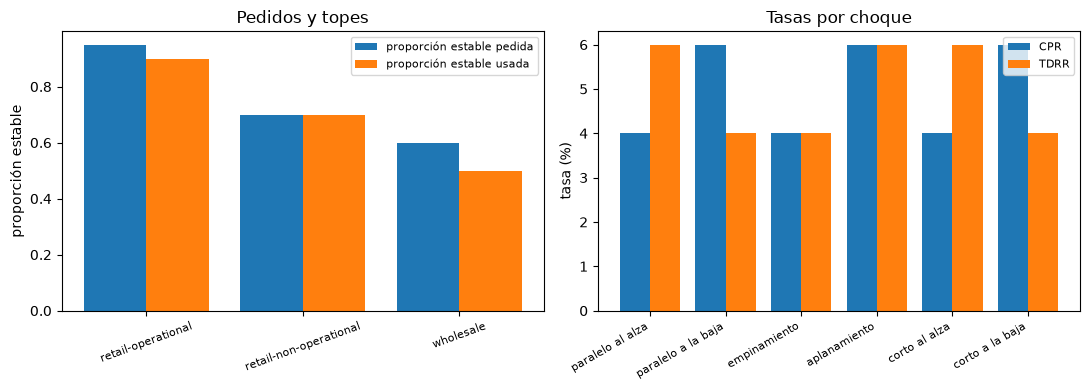

In [5]:
# Dividir los tres segmentos de depósitos con los topes del motor y escalar las tasas base del banco por choque
asked, used = [], []
for seg in out["nmd_segments"]:
    args = (seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    r = slotting.nmd_split(*args)
    asked.append(seg["requested_core_share"])
    used.append(r.core_share_used)
    print(f"{seg['category']:24s} pedido {asked[-1]:.2f}/{seg['requested_core_maturity_years']:.1f} y")
    print(f"    -> {r.core_share_used:.2f}/{r.core_maturity_used_years:.1f} y | tope aplicado {NAME[r.cap_applied]}")
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
print(f"tasas base: CPR {cpr0:.2f} | TDRR {tdrr0:.2f}")
cpr_s = [slotting.prepayment_cpr(s, cpr0) for s in shocks.SHOCKS]
tdrr_s = [slotting.term_deposit_redemption_rate(s, tdrr0) for s in shocks.SHOCKS]
for s, c, t in zip(shocks.SHOCKS, cpr_s, tdrr_s):
    print(f"{NAME[s]:22s} CPR {c:.4f} | TDRR {t:.4f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.bar(np.arange(3) - 0.2, asked, 0.4, label="proporción estable pedida")
left.bar(np.arange(3) + 0.2, used, 0.4, label="proporción estable usada")
left.set_xticks(np.arange(3), [s["category"] for s in out["nmd_segments"]], rotation=20, fontsize=8)
left.set_ylabel("proporción estable")
left.set_title("Pedidos y topes")
left.legend(fontsize=8)
right.bar(np.arange(6) - 0.2, np.array(cpr_s) * 100, 0.4, label="CPR")
right.bar(np.arange(6) + 0.2, np.array(tdrr_s) * 100, 0.4, label="TDRR")
right.set_xticks(np.arange(6), [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
right.set_ylabel("tasa (%)")
right.set_title("Tasas por choque")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

A la izquierda el segmento minorista operacional pide 95 por ciento estable y se corta a 90, el mayorista pide 60 y se corta a 50, y el minorista no operacional pide exactamente su tope, 70, y no se corta: los pedidos del banco a veces están sobre el estándar y a veces en él. A la derecha los multiplicadores doblan las tasas base de 5 por ciento: el prepago baja a 4 por ciento bajo los choques paralelo al alza, empinamiento y corto al alza y sube a 6 por ciento bajo los otros tres, y el rescate anticipado de depósitos a plazo se mueve al revés en los choques paralelo al alza, aplanamiento y corto al alza. La figura muestra cómo responden los supuestos a un choque, no si las tasas base son correctas: son sintéticas.

### Paso 4: el delta EVE de cada tramo

Para cada uno de los seis choques y cada tramo, el Anexo descuenta los flujos base y los flujos con choque y toma la diferencia, con la pérdida positiva (SRP31.129, repetido en el Anexo, Hojas 10 a 12):

$$\Delta EVE_{i,c} = \sum_{k=1}^{19} CF_{0,c}(t_k)\, DF_{0,c}(t_k) - \sum_{k=1}^{19} CF_{i,c}(t_k)\, DF_{i,c}(t_k) + KAO_{i,c}, \qquad DF_{i,c}(t_k) = e^{-r_{i,c}(t_k)\, t_k}$$

donde $c$ es la moneda (CLP o UR), $i$ el choque y $KAO$ el cargo por opciones automáticas (cero aquí). La tasa con choque es la tasa base más la forma del notebook 02 con los tamaños de la tabla chilena (CLP 300, 400 y 200 pb; UR 200, 250 y 150 pb), con piso en 0 por ciento para el peso y en -2 por ciento para la UR. Los flujos con choque son los flujos base con el rescate anticipado de depósitos a plazo movido a la banda a la vista a la tasa del multiplicador del choque; el documento los guarda como `net_cash_flows`. La celda siguiente reconstruye los flujos base desde las partidas (el tramo UR convertido al valor de la UF, pues el motor nunca convierte), aplica choque y piso a las curvas con `shock_curve` y `apply_floor`, y llama a `delta_eve` para los seis choques y los dos tramos.

paralelo al alza           34,216.3     45,427.0
paralelo a la baja        -39,940.6    -69,821.5
empinamiento               -8,821.7     38,748.2
aplanamiento               16,210.5    -32,556.6
corto al alza              28,675.1     -3,889.5
corto a la baja           -26,245.2      5,720.7


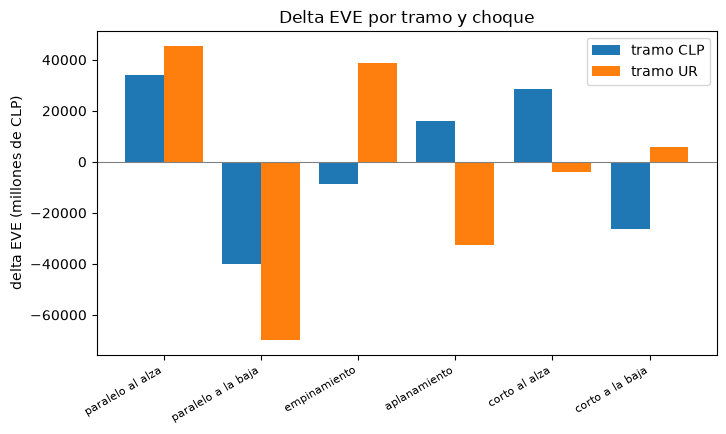

In [6]:
# Reconstruir los flujos base de cada tramo, aplicar choque y piso, y llamar a delta_eve en los seis choques
conv = {"CLP": 1.0, "UR": uf}
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
sizes = {"CLP": shocks.shock_size("CLP", "cmf-annex1"), "UR": shocks.shock_size("CLF", "cmf-annex1")}
base = {}
for leg in out["legs"]:
    rows = [r for item in leg["items"] for r in item["cash_flows"]]
    buckets, amounts = [r["bucket"] - 1 for r in rows], [r["amount"] for r in rows]
    base[leg["leg"]] = conv[leg["leg"]] * np.bincount(buckets, weights=amounts, minlength=19)
delta_eve = {"CLP": [], "UR": []}
for row in out["eve"]["rows"]:
    for leg, key in (("CLP", "clp"), ("UR", "ur")):
        z = sizes[leg]
        shape = shocks.shock_curve(row["shock"], z.parallel_bp, z.short_bp, z.long_bp, MID)
        shocked = shocks.apply_floor(r0[leg], shape, floors[leg])
        flows = np.array(row[key]["net_cash_flows"])
        delta_eve[leg].append(eve_nii.delta_eve(base[leg], flows, r0[leg], shocked, MID))
    print(f"{NAME[row['shock']]:22s} {delta_eve['CLP'][-1]:12,.1f} {delta_eve['UR'][-1]:12,.1f}")
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, delta_eve["CLP"], 0.4, label="tramo CLP")
ax.bar(x + 0.2, delta_eve["UR"], 0.4, label="tramo UR")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("delta EVE (millones de CLP)")
ax.set_title("Delta EVE por tramo y choque")
ax.legend()
plt.show()

Se leen las barras choque por choque. El choque paralelo al alza pierde en ambos tramos, 34.216 en pesos y 45.427 en la UR, así que será el choque que decida la medida; el paralelo a la baja gana en ambos. El empinamiento y el aplanamiento dividen los tramos, una pérdida de la UR y una ganancia de los pesos en el empinamiento y al revés en el aplanamiento, justo donde la regla de compensación actuará en el paso siguiente. La imagen muestra los deltas de cada tramo por separado: todavía no dice nada de la medida del Anexo, que combina los tramos. Muestra además que el tramo UR, un libro de pocos millones de UF, mueve el EVE tanto como el tramo en pesos porque es más largo.

### Paso 5: la compensación de 50 por ciento y el delta EVE del Anexo 1

Un movimiento de la tasa en pesos y uno de la tasa en UF son en parte independientes, así que el Anexo no suma sin más las pérdidas de los dos tramos. Cuando los deltas del peso y de la UR tienen **signos opuestos**, la mitad del tramo con ganancia compensa al tramo con pérdida, con piso en cero (Anexo 1, Hojas 10 a 12; dossier 03, F.2):

$$\Delta_{CLP+CLF} = \begin{cases} \max(0{,}5\, \Delta_{CLP} + \Delta_{CLF},\ 0) & \text{si } \Delta_{CLP} \le 0 < \Delta_{CLF} \\ \max(\Delta_{CLP} + 0{,}5\, \Delta_{CLF},\ 0) & \text{si } \Delta_{CLF} \le 0 < \Delta_{CLP} \\ \max(\Delta_{CLP}, 0) + \max(\Delta_{CLF}, 0) & \text{en otro caso} \end{cases}$$

El 50 por ciento se aplica solo al tramo con ganancia. El delta EVE del Anexo es el máximo entre los seis choques del par, más la parte positiva de cualquier otra moneda significativa (ninguna aquí). La función `cmf_pair` del motor es el par y `annex1_delta_eve` el máximo. La primera celda de abajo muestra la regla en ocho pares de números ilustrativos, con y sin compensación; la segunda la aplica al banco.

  Δ CLP   Δ CLF   con compensación     sin compensación
     10      20               30.0                 30.0
    -10     -20                0.0                  0.0
     30     -20               20.0                 30.0
    -20      30               20.0                 30.0
     10     -40                0.0                 10.0
    -40      10                0.0                 10.0
      0      25               25.0                 25.0
     25       0               25.0                 25.0


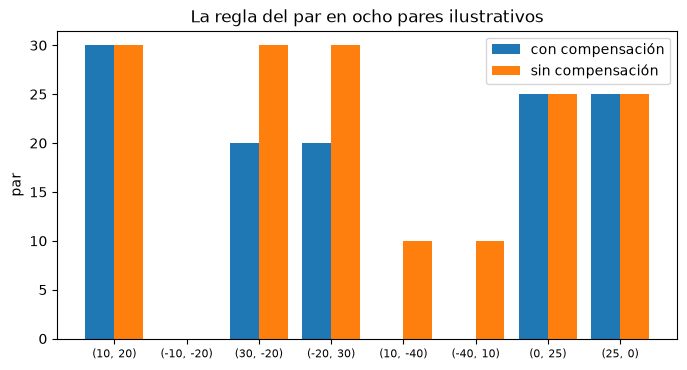

In [7]:
# La regla de compensación en ocho pares ilustrativos, con y sin compensación
cases = ((10, 20), (-10, -20), (30, -20), (-20, 30), (10, -40), (-40, 10), (0, 25), (25, 0))
with_off = [eve_nii.cmf_pair(clp, clf, True) for clp, clf in cases]
without = [eve_nii.cmf_pair(clp, clf, False) for clp, clf in cases]
print(f"{'Δ CLP':>7s} {'Δ CLF':>7s} {'con compensación':>18s} {'sin compensación':>20s}")
for (clp, clf), a, b in zip(cases, with_off, without):
    print(f"{clp:7d} {clf:7d} {a:18.1f} {b:20.1f}")
x = np.arange(len(cases))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, with_off, 0.4, label="con compensación")
ax.bar(x + 0.2, without, 0.4, label="sin compensación")
ax.set_xticks(x, [f"({clp}, {clf})" for clp, clf in cases], fontsize=8)
ax.set_ylabel("par")
ax.set_title("La regla del par en ocho pares ilustrativos")
ax.legend()
plt.show()

Las dos barras difieren solo donde los signos de los dos tramos son opuestos. Para (30, -20) el tramo con pérdida paga 30 y el tramo con ganancia de 20 compensa la mitad de sí mismo, 10, así que el par es 20 con compensación y 30 sin ella; para (10, -40) la mitad de 40 es 20, más que la pérdida de 10, así que el par queda en cero por el piso. Cuando ambos tramos pierden, (10, 20) o (0, 25), o ambos ganan, (-10, -20), la compensación no hace nada. Son números ilustrativos y no el banco, elegidos para mostrar los cuatro regímenes de la regla: la figura es la regla, no un hallazgo.

Ahora el banco. La celda siguiente aplica la regla del par a los seis pares de deltas por tramo del Paso 4 y toma el máximo, con la compensación que usa la variante y, para comparar, sin ella.

paralelo al alza             79,643.4       79,643.4
paralelo a la baja                0.0            0.0
empinamiento                 34,337.4       38,748.2
aplanamiento                      0.0       16,210.5
corto al alza                26,730.3       28,675.1
corto a la baja                   0.0        5,720.7
delta EVE del Anexo 1 79,643.4 (peor choque: paralelo al alza)
estado de la compensación en esta variante: con
proporción del tramo con ganancia que compensa: 0.5
delta EVE como proporción del Tier 1: 0.0966


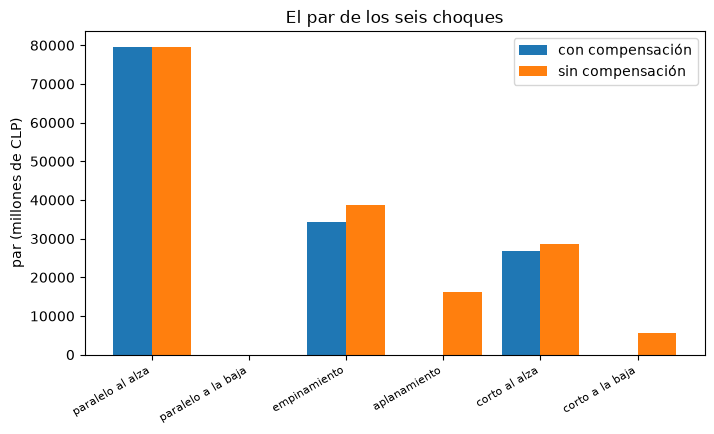

In [8]:
# Aplicar la regla del par y el máximo a los seis choques del banco, con y sin compensación
offset = out["offset_rule"]["state"] != "off"
d_clp, d_ur = np.array(delta_eve["CLP"]), np.array(delta_eve["UR"])
a1 = eve_nii.annex1_delta_eve(d_clp, d_ur, offset)
no_offset = eve_nii.annex1_delta_eve(d_clp, d_ur, False)
for k, s in enumerate(shocks.SHOCKS):
    print(f"{NAME[s]:22s} {a1.pairs[k]:14,.1f} {no_offset.pairs[k]:14,.1f}")
print(f"delta EVE del Anexo 1 {a1.delta_eve:,.1f} (peor choque: {NAME[a1.worst_shock]})")
print("estado de la compensación en esta variante:", NAME[out["offset_rule"]["state"]])
print("proporción del tramo con ganancia que compensa:", out["offset_rule"]["share"])
print("delta EVE como proporción del Tier 1:", round(a1.delta_eve / out["thresholds"]["tier1"], 4))
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, a1.pairs, 0.4, label="con compensación")
ax.bar(x + 0.2, no_offset.pairs, 0.4, label="sin compensación")
ax.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("par (millones de CLP)")
ax.set_title("El par de los seis choques")
ax.legend()
plt.show()

Para el banco la compensación actúa en las dos rotaciones y en los choques cortos: el par del empinamiento es 34.337 con compensación y 38.748 sin ella, el del aplanamiento es 0 con ella y 16.211 sin ella, y el choque paralelo a la baja es 0 de ambas formas porque los dos tramos ganan. El peor choque es el paralelo al alza con 79.643, la suma de las dos pérdidas, donde la compensación no hace nada, así que la medida del Anexo es la misma con y sin ella. Es el punto general: la compensación cambia la medida solo cuando cambia el peor choque, y para este banco no lo hace. El delta EVE es 9,66 por ciento del Tier 1, bajo la línea de 15 por ciento, que los últimos pasos ponen a prueba.

### Paso 6: el delta NII y el cargo por reajustabilidad

El delta NII usa un **único choque paralelo de 300 pb para ambos tramos**, al alza y a la baja, sobre los flujos del primer año, ponderados por el tiempo que queda del año, con la pérdida positiva (Anexo 1, Hoja 10; dossier 03, F.2):

$$\Delta NII_{i,c} = \sum_{t_k < 1} CF_c(t_k)\, \big(r_{0,c}(t_k) - r_{i,c}(t_k)\big)\, (1 - t_k)$$

Los dos tramos se emparejan con la misma regla de compensación, se toma el máximo entre los dos choques, y el **cargo por reajustabilidad** se suma una sola vez, después del máximo:

$$\Delta NII = \max_{i \in \{alza,\ baja\}} \Delta NII_{i,(CLP+CLF)} + 2{,}5\% \cdot |PN_{UR}|$$

El cargo es "el cargo estándar por reajustabilidad", una sorpresa de inflación implícita de 2,5 por ciento sobre la posición neta en UF en valor absoluto. La función `delta_nii` del motor es el tramo, `indexation_charge` el cargo y `annex1_delta_nii` el conjunto. La celda siguiente recalcula las cuatro cifras de los dos choques y los dos tramos, y luego la medida del Anexo.

paralelo al alza choque +300 pb | ΔNII CLP   -7,059.4
    ΔNII UR    8,414.9
paralelo a la baja choque -300 pb | ΔNII CLP    7,059.4
    ΔNII UR   -8,414.9
pares (alza, baja) [4885.3 2851.9] | par máximo 4,885.3 (paralelo al alza)
cargo 6,181.6 | ΔNII 11,066.9
el cargo como proporción del delta NII: 0.5586


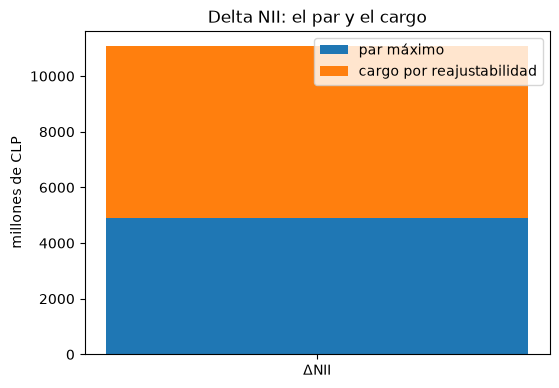

In [9]:
# Recalcular el delta NII de cada tramo para +300 y -300 pb, emparejar los tramos y sumar el cargo por reajustabilidad
delta_nii = {"CLP": [], "UR": []}
for row in out["nii"]["rows"]:
    bp = row["clp"]["shock_bp"]
    for leg in ("CLP", "UR"):
        shocked = shocks.apply_floor(r0[leg], np.full(19, bp), floors[leg])
        delta_nii[leg].append(eve_nii.delta_nii(base[leg], r0[leg], shocked, MID))
    print(f"{NAME[row['shock']]:16s} choque {bp:+.0f} pb | ΔNII CLP {delta_nii['CLP'][-1]:10,.1f}")
    print(f"    ΔNII UR {delta_nii['UR'][-1]:10,.1f}")
a2 = eve_nii.annex1_delta_nii(np.array(delta_nii["CLP"]), np.array(delta_nii["UR"]), pn_ur, offset)
print(f"pares (alza, baja) {np.round(a2.pairs, 1)} | par máximo {a2.max_pair:,.1f} ({NAME[a2.worst_shock]})")
print(f"cargo {a2.indexation_charge:,.1f} | ΔNII {a2.delta_nii:,.1f}")
print("el cargo como proporción del delta NII:", round(a2.indexation_charge / a2.delta_nii, 4))
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.bar(["ΔNII"], [a2.max_pair], label="par máximo")
ax.bar(["ΔNII"], [a2.indexation_charge], bottom=[a2.max_pair], label="cargo por reajustabilidad")
ax.set_ylabel("millones de CLP")
ax.set_title("Delta NII: el par y el cargo")
ax.legend()
plt.show()

La barra única es el delta NII del Anexo armado en dos bloques: el par máximo de los dos choques de 300 pb, 4.885 con compensación, y el cargo por reajustabilidad, 6.182, sumado una vez después del máximo. Más de la mitad de la medida, 55,9 por ciento, es el cargo, que no depende del choque ni de los deltas de los tramos sino del tamaño de la posición neta en UF. Los pesos ganan cuando suben las tasas (-7.059) y la UR pierde (8.415), así que el par con compensación es 4.885 frente a 8.415 sin ella. La imagen muestra la composición de la medida; no muestra que un cargo de este tamaño sea una buena estimación del riesgo de inflación, solo que el Anexo lo fija así.

Un detalle del código de la celda anterior que vale la pena leer: los tramos del primer choque tienen signos opuestos (el peso pierde cuando la tasa baja y la UF cuando sube, o al revés), así que la regla de compensación actúa también en el NII. El cargo, en cambio, no depende del choque ni de los deltas de los tramos: depende del tamaño de la posición neta en UF y de nada más, y es positivo sea cual sea el signo de la posición. La variante de sorpresa de IPC lo hace concreto. Una posición neta larga en UF gana con la inflación, y paga el mismo cargo que una corta. La celda siguiente imprime el cargo y el escenario de IPC de las variantes larga y corta.

short-uf      PN_UR   -247,264.2 | cargo (motor)   6,181.6
long-uf       PN_UR    247,264.2 | cargo (motor)   6,181.6
cpi-surprise  PN_UR    247,264.2 | cargo (motor)   6,181.6
    sorpresa de IPC +2.5 pp | efecto (pérdida positiva) -6,181.6


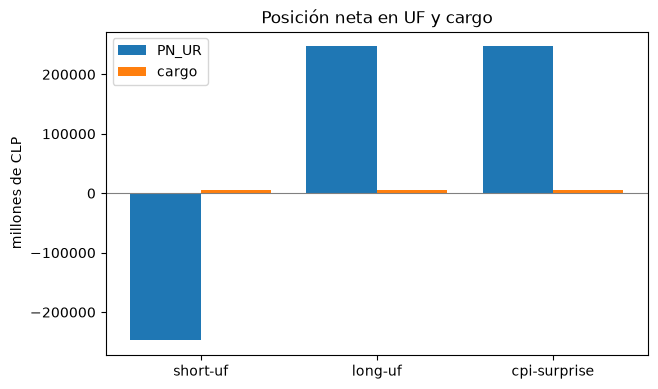

In [10]:
# El cargo por reajustabilidad con el motor para una posición corta y una larga en UF, y la sorpresa de IPC
positions, charges = [], []
for v in ("short-uf", "long-uf", "cpi-surprise"):
    o = variants[v]["outputs"]
    position = o["legs"][1]["net_position"] * o["ur_currency"]["uf_value"]
    charge = eve_nii.indexation_charge(position)
    positions.append(position)
    charges.append(charge)
    print(f"{v:13s} PN_UR {position:12,.1f} | cargo (motor) {charge:9,.1f}")
    cs = o["cpi_scenario"]
    if cs:
        print(f"    sorpresa de IPC +{cs['surprise_pp']:.1f} pp | efecto (pérdida positiva) {cs['effect']:,.1f}")
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(x - 0.2, positions, 0.4, label="PN_UR")
ax.bar(x + 0.2, charges, 0.4, label="cargo")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, ["short-uf", "long-uf", "cpi-surprise"])
ax.set_ylabel("millones de CLP")
ax.set_title("Posición neta en UF y cargo")
ax.legend()
plt.show()

Las barras de posición son imágenes en espejo, -247.264 para el banco corto y +247.264 para los largos, y las barras del cargo tienen la misma altura, 6.182, en los tres: el cargo es unilateral y depende de la posición absoluta. El escenario de IPC, en cambio, es bilateral: una sorpresa de inflación de 2,5 puntos es una pérdida de 6.182 para una posición corta y una ganancia, un efecto de -6.182 en la convención de pérdida positiva, para una larga. El cargo estándar es entonces un recargo que un banco largo neto paga aunque gane con la sorpresa; el escenario muestra qué hace el mismo movimiento de inflación a cada banco. La imagen es un par de bancos y una sorpresa; no describe la distribución de la inflación.

### Paso 7: las pruebas de banco priorizado

El Anexo hace **priorizado** a un banco para la revisión detallada del supervisor si alguna de tres razones está estrictamente sobre su línea: el delta NII sobre el Tier 1 sobre 5 por ciento, el delta EVE sobre el Tier 1 sobre 15 por ciento, o el delta NII sobre el margen neto de intereses y reajustes acumulado a 12 meses sobre 18 por ciento (dossier 03, F.2). La función `prioritised_bank` del motor recibe las dos medidas, el Tier 1 y el margen, y devuelve las tres pruebas. El Tier 1 y el margen están en el documento (el margen es el NII base de la proyección dinámica de los dos tramos, en las mismas unidades). La celda siguiente la aplica a las cifras recién recalculadas.

Tier 1: 824213.8
margen a 12 meses: 274664.5
nii-tier1  medida    11,066.9 /   824,213.8 = 0.0134
    línea 0.05 | no
eve-tier1  medida    79,643.4 /   824,213.8 = 0.0966
    línea 0.15 | no
nii-margin medida    11,066.9 /   274,664.5 = 0.0403
    línea 0.18 | no
priorizado: no


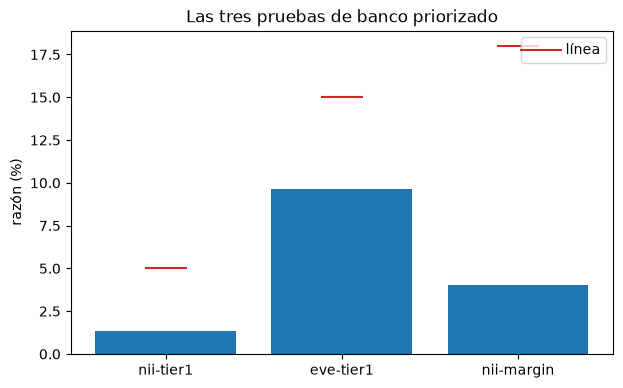

In [11]:
# Aplicar las tres pruebas de banco priorizado a las medidas recalculadas
th = out["thresholds"]
pb = eve_nii.prioritised_bank(a2.delta_nii, a1.delta_eve, th["tier1"], th["net_interest_and_indexation_margin_12m"])
margin = th["net_interest_and_indexation_margin_12m"]
print("Tier 1:", round(th["tier1"], 1))
print("margen a 12 meses:", round(margin, 1))
for test in pb.tests:
    print(f"{test['id']:10s} medida {test['measure']:11,.1f} / {test['base']:11,.1f} = {test['ratio']:.4f}")
    print(f"    línea {test['threshold']:.2f} | {NAME[test['breached']]}")
print("priorizado:", NAME[pb.prioritised])
fig, ax = plt.subplots(figsize=(7, 4.2))
names = [t["id"] for t in pb.tests]
ax.bar(names, [t["ratio"] * 100 for t in pb.tests], color="tab:blue")
ax.scatter(names, [t["threshold"] * 100 for t in pb.tests], color="tab:red", marker="_", s=900, label="línea")
ax.set_ylabel("razón (%)")
ax.set_title("Las tres pruebas de banco priorizado")
ax.legend()
plt.show()

Las tres barras quedan bien bajo sus líneas rojas: el delta NII es 1,34 por ciento del Tier 1 frente a una línea de 5, el delta EVE 9,66 por ciento frente a 15, y el delta NII 4,03 por ciento del margen a 12 meses frente a 18. El banco no es priorizado, y lo más cerca de una línea es el delta EVE, a cerca de dos tercios del camino. La prueba es estricta, una razón estrictamente sobre su línea, así que un banco en exactamente 15 por ciento no es priorizado. La imagen es una variante, el banco corto neto en UF; el paso siguiente la compara con las otras, una de las cuales sí cruza una línea.

### Paso 8: los pisos

El Anexo pone a las tasas posteriores al choque un piso de 0 por ciento para el peso y de -2 por ciento para la UR (el notebook 02 mostró la regla). El documento guarda, para cada tramo, medida y choque, la tasa más baja posterior al choque antes del piso, su banda y su distancia al piso en puntos base; una distancia de cero o menos significa que el piso actúa. La función `apply_floor` del motor se llama aquí sin piso para leer la tasa con choque en bruto. La celda siguiente recalcula las distancias para los choques de NII de 300 pb y los seis choques de EVE de ambos tramos, lista las menores, y luego revisa las seis variantes buscando algún piso que actúe.

UR   delta NII  paralelo a la baja     banda  1 |    20.48
CLP  delta EVE  corto a la baja        banda  1 |    50.21
UR   delta EVE  corto a la baja        banda  1 |    70.65
UR   delta EVE  paralelo a la baja     banda  1 |   120.48
CLP  delta EVE  paralelo a la baja     banda  3 |   148.68
CLP  delta NII  paralelo a la baja     banda  3 |   148.68
pisos que actúan en cada variante: {'short-uf': 0, 'long-uf': 0, 'cpi-surprise': 0, 'clp-steepener': 0, 'offset-on-off': 0, 'floors-active': 0}
menor distancia en cada variante (pb): {'short-uf': 20.48, 'long-uf': 20.48, 'cpi-surprise': 20.48, 'clp-steepener': 20.48, 'offset-on-off': 20.48, 'floors-active': 20.48}


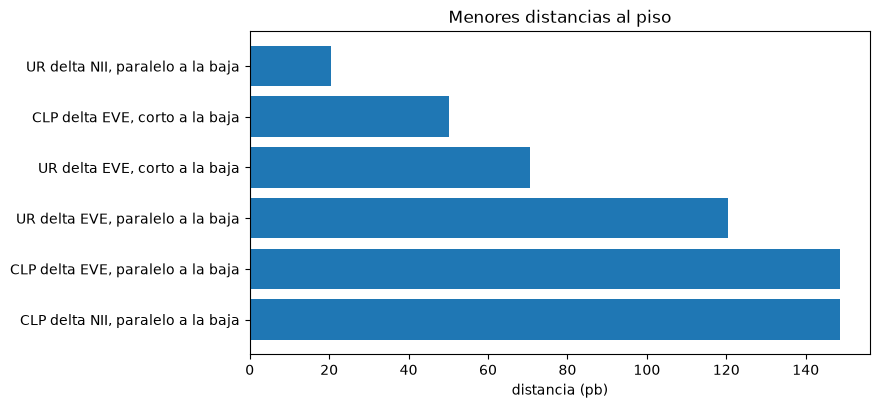

In [12]:
# Recalcular la distancia de cada tasa con choque a su piso, listar las menores y buscar pisos que actúen
rows = []
for leg in ("CLP", "UR"):
    z = sizes[leg]
    for s in shocks.SHOCKS:
        raw = shocks.apply_floor(r0[leg], shocks.shock_curve(s, z.parallel_bp, z.short_bp, z.long_bp, MID), None)
        rows.append((leg, "delta-eve", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
    for s, bp in (("parallel-up", 300.0), ("parallel-down", -300.0)):
        raw = shocks.apply_floor(r0[leg], np.full(19, bp), None)[:6]
        rows.append((leg, "delta-nii", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
smallest = sorted(rows, key=lambda r: r[4])[:6]
for leg, measure, shock, band, distance in smallest:
    print(f"{leg:4s} {NAME[measure]:10s} {NAME[shock]:22s} banda {band:2d} | {distance:8.2f}")
print("pisos que actúan en cada variante:", {v: len(d["outputs"]["floors"]["effects"]) for v, d in variants.items()})
mins = {v: round(min(x["distance_bp"] for x in d["outputs"]["floors"]["distances"]), 2) for v, d in variants.items()}
print("menor distancia en cada variante (pb):", mins)
labels = [f"{leg} {NAME[m]}, {NAME[s]}" for leg, m, s, _, _ in smallest]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(labels, [r[4] for r in smallest], color="tab:blue")
ax.set_xlabel("distancia (pb)")
ax.set_title("Menores distancias al piso")
ax.invert_yaxis()
plt.show()

Las barras son las seis menores distancias entre una tasa con choque y su piso, en puntos base, y ninguna es cero, así que ningún piso actúa. La más cercana es la tasa UR de la primera banda bajo la baja de 300 pb en la medida de NII, a 20,48 pb de su piso de -2 por ciento; siguen el choque corto a la baja en pesos del EVE a 50,21 pb, y luego 70,65 y 120,48 pb. El listado de las seis variantes confirma que ningún piso actúa en ninguna, incluida `floors-active`, que se construyó con 70 por ciento de los préstamos comerciales en UF a tasa flotante para poner en juego los pisos y no lo logra. Con las tasas en los niveles de hoy el piso es una regla que el motor implementa y prueba, no una que mueva un número aquí.

### Paso 9: las seis variantes

El último paso pone las seis variantes lado a lado. Para cada variante la celda toma los deltas por tramo del documento versionado, los pasa a `annex1_delta_eve`, `annex1_delta_nii` y `prioritised_bank` del motor, e imprime las medidas del Anexo, las razones y si el banco es priorizado. La figura dibuja el delta EVE sobre el Tier 1 y el delta NII sobre el Tier 1 contra sus líneas.

                     ΔEVE  ΔEVE/T1      ΔNII  ΔNII/T1
short-uf           79,643   0.0966    11,067   0.0134
    priorizado: no | compensación: con
long-uf            93,816   0.1138    11,213   0.0136
    priorizado: no | compensación: con
cpi-surprise       93,816   0.1138    11,213   0.0136
    priorizado: no | compensación: con
clp-steepener     140,645   0.1706     6,783   0.0082
    priorizado: sí | compensación: con
offset-on-off      81,173   0.0985    11,016   0.0134
    priorizado: no | compensación: comparada
floors-active      60,764   0.0737     6,606   0.0080
    priorizado: no | compensación: con


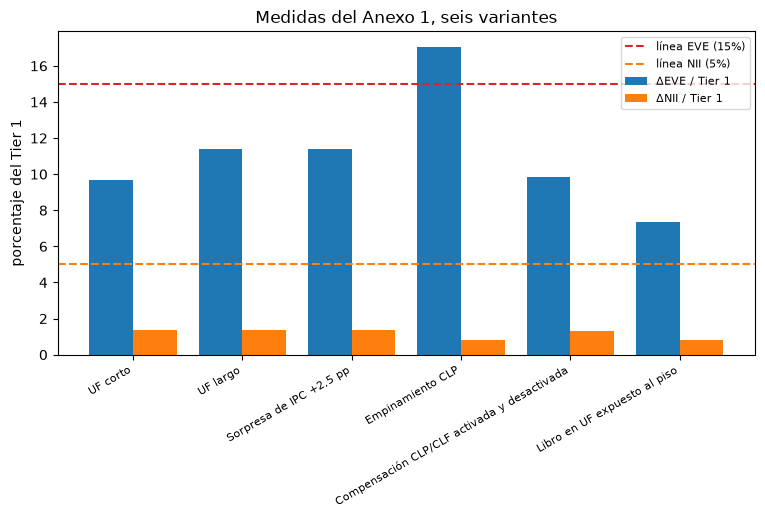

In [13]:
# Por variante: las medidas del Anexo desde los deltas por tramo con el motor, las razones y la marca de priorizado
summary = {}
print(f"{'':14s} {'ΔEVE':>10s} {'ΔEVE/T1':>8s} {'ΔNII':>9s} {'ΔNII/T1':>8s}")
for v, d in variants.items():
    o = d["outputs"]
    on = o["offset_rule"]["state"] != "off"
    rows_e, rows_n = o["eve"]["rows"], o["nii"]["rows"]
    pair_e = [np.array([r["pair"][k] for r in rows_e]) for k in ("delta_clp", "delta_ur")]
    pair_n = [np.array([r["pair"][k] for r in rows_n]) for k in ("delta_clp", "delta_ur")]
    m_eve = eve_nii.annex1_delta_eve(*pair_e, on)
    m_nii = eve_nii.annex1_delta_nii(*pair_n, o["indexation_charge"]["pn_ur"], on)
    t = o["thresholds"]
    margin = t["net_interest_and_indexation_margin_12m"]
    flag = eve_nii.prioritised_bank(m_nii.delta_nii, m_eve.delta_eve, t["tier1"], margin)
    ratio = {x["id"]: x["ratio"] for x in flag.tests}
    summary[v] = (ratio["eve-tier1"], ratio["nii-tier1"], flag.prioritised)
    eve_part = f"{m_eve.delta_eve:10,.0f} {ratio['eve-tier1']:8.4f}"
    print(f"{v:14s} {eve_part} {m_nii.delta_nii:9,.0f} {ratio['nii-tier1']:8.4f}")
    print(f"    priorizado: {NAME[flag.prioritised]} | compensación: {NAME[o['offset_rule']['state']]}")
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(ids))
ax.bar(x - 0.2, [summary[v][0] * 100 for v in ids], 0.4, label="ΔEVE / Tier 1")
ax.bar(x + 0.2, [summary[v][1] * 100 for v in ids], 0.4, label="ΔNII / Tier 1")
ax.axhline(15, color="tab:red", linestyle="--", label="línea EVE (15%)")
ax.axhline(5, color="tab:orange", linestyle="--", label="línea NII (5%)")
ax.set_xticks(x, [variants[v]["outputs"]["variant"]["label"][LANG] for v in ids], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("porcentaje del Tier 1")
ax.set_title("Medidas del Anexo 1, seis variantes")
ax.legend(fontsize=8)
plt.show()

Solo una barra cruza una línea roja: la variante de empinamiento en pesos, un balance en pesos más largo, tiene un delta EVE de 17,06 por ciento del Tier 1 frente a la línea de 15, y es el único banco priorizado de los seis. Las variantes long-uf y cpi-surprise comparten sus números, 11,38 por ciento, porque el escenario de IPC cambia el efecto de la inflación y no la medida del Anexo, y son las más cercanas de las otras. Las barras de delta NII están todas bajo la línea de 5 por ciento, entre 0,80 y 1,36 por ciento. La imagen son seis variantes sintéticas de un banco sintético: muestra qué tensión mueve las medidas del Anexo, no el riesgo de ningún banco real.

## Resultados

**Respuesta:** el Anexo 1 pone al banco corto neto en UF en un delta EVE de 79.643 millones de CLP, 9,66 por ciento del Tier 1, decidido por el choque paralelo al alza donde ambos tramos pierden, y en un delta NII de 11.067, de los cuales 6.182 son el cargo por reajustabilidad, 1,34 por ciento del Tier 1. El banco no es priorizado, porque ninguna razón cruza su línea, y ningún piso actúa. Solo la variante de empinamiento en pesos cruza una línea, un delta EVE de 17,06 por ciento del Tier 1, y es priorizada.

- **Los dos tramos.** El tramo en pesos tiene activos de 4.988.540 y pasivos de 3.917.062 (millones de CLP), una posición neta activa de 1.071.478. El tramo UR es diminuto en su propia unidad, 65,89 y 71,94 millones de CLF, pero a 40.877,73 pesos por UF su posición neta de -6,05 millones de CLF es -247.264 millones de CLP, el -30 por ciento del Tier 1 que la variante está construida para tener. Esa posición, y no el tamaño del libro en UF, fija el cargo.
- **Las curvas.** La curva en pesos tiene un decaimiento Nelson-Siegel de 1 año y un error de 0,50 pb, la curva UF un decaimiento de 2,5 años y 0,41 pb. En la banda más corta la curva en pesos está en 0,04499 y la UF en 0,01205: la curva nominal queda unos 3 puntos sobre la real. La curva en pesos se apoya en tres rendimientos de mercado y la tasa de política, así que su punto más corto es una tasa de política y no de mercado; un validador debe leerlo como una elección abierta, no como una medición.
- **Topes y multiplicadores.** El segmento minorista operacional pide 0,95 y 5,5 años y se corta a 0,90 y 5,0 años, el mayorista pide 0,60 y 4,5 años y se corta a 0,50 y 4,0 años, y el minorista no operacional pide exactamente sus topes y no se corta. Con un prepago base de 0,05, los choques paralelo al alza, empinamiento y corto al alza dan 0,0400 y los otros tres 0,0600.
- **El delta EVE.** Ambos tramos pierden bajo el choque paralelo al alza (34.216,3 en pesos y 45.427,0 en la UR), que es el peor choque, así que el par es su suma, 79.643,4, y la compensación no hace nada. Donde los tramos van en direcciones opuestas la compensación actúa: en el empinamiento el par es 34.337,4 con ella y 38.748,2 sin ella, en el aplanamiento 0,0 con ella y 16.210,5 sin ella. La compensación cambia la medida del Anexo solo si cambia el peor choque, como muestra la variante offset-on-off.
- **El delta NII y el cargo.** Los pesos ganan cuando suben las tasas (-7.059,4) y la UR pierde (8.414,9): el par con compensación es 4.885,3. El cargo es 6.181,6, 0,5586 del delta NII de 11.066,9: más de la mitad de la medida de NII es función del tamaño de la posición neta en UF, no del choque. El cargo es el mismo para una posición corta neta de -247.264,2 y una larga neta de 247.264,2, mientras que una sorpresa de inflación de 2,5 puntos es una pérdida para el banco corto y una ganancia para el largo: el cargo estándar es un recargo unilateral, el escenario es bilateral.
- **Las pruebas.** El banco corto en UF está en 0,0134 del Tier 1 para el delta NII (línea 0,05), en 0,0966 para el delta EVE (línea 0,15) y en 0,0403 del margen a 12 meses (línea 0,18): no priorizado. La variante long-uf, con 0,1138, es la más cercana de las otras a la línea del EVE.
- **Los pisos.** Ningún piso actúa en ninguna de las seis variantes. La tasa con choque más cercana es la UR de la primera banda bajo una baja de 300 pb, a 20,48 pb de un piso de -2 por ciento; siguen 50,21 pb, 70,65 y 120,48 pb. La variante `floors-active` no pone en juego los pisos: su nombre declara la intención, no el resultado.
- **Lo que el notebook no muestra.** El NII dinámico y las distribuciones de Hull-White de los dos tramos, los precios de la propia indexación a la UF (la tasa real está en la curva, la inflación está en el cargo), y cualquier verificación de las cifras chilenas contra una segunda implementación: no hay ninguna con la cual comparar (notebook 08).

## Resumen

- El Anexo chileno trata la UF como una sola moneda, la UR, con su propia curva, sus propios tamaños de choque, un piso en -2 por ciento y un cargo por reajustabilidad de 2,5 por ciento de la posición neta absoluta en UF; el motor implementa cada pieza y nunca convierte entre monedas.
- El delta EVE toma los seis choques en cada tramo, empareja los tramos con la compensación de 50 por ciento sobre el tramo con ganancia y toma el peor choque; el delta NII usa un solo choque de 300 pb, el mismo emparejamiento y suma el cargo una vez.
- El cargo no depende del choque ni del signo de la posición, así que un banco largo neto en UF, que gana con la inflación, paga lo mismo que uno corto neto.
- Tres pruebas hacen priorizado a un banco: el delta NII sobre 5 por ciento del Tier 1, el delta EVE sobre 15 por ciento y el delta NII sobre 18 por ciento del margen a 12 meses; una de las seis variantes cruza una línea.
- Ningún piso actúa en las seis variantes; la tasa con choque más cercana está a 20,48 pb de su piso, en el tramo UR bajo una baja de 300 pb.

**Qué probar a continuación.** Elige la variante `long-uf` como la principal en la primera celda y mira cómo cambia el par del primer choque. Después sigue con el notebook 07, la literatura publicada.

## Referencias

- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1, Determinación de la exposición al riesgo de mercado en el libro de banca (Circulares 2.270 de 2020 y 2.365 de 2025). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31 (los choques, las bandas, los topes y los multiplicadores, repetidos por el Anexo). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- CMF, Informe del Desempeño del Sistema Bancario y Cooperativas, agosto de 2026, Cuadro N 1 (los agregados del banco sintético). https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- Banco Central de Chile, Base de Datos Estadísticos, cuadro F022 (rendimientos de mercado secundario) y serie F073.UFF.PRE.Z.D (la UF), términos de uso. https://si3.bcentral.cl/estadisticas/Principal1/Web_Services/terminos_condiciones.html
- Nelson, C. R. y Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Dossier 03 de la investigación de Contraste (Chile), sección F.2.